# MeanFlow on a 2D toy

Juntang Wang, Hacker, CS 2883R, 14 Oct. Paper: Geng, Deng, Bai, Kolter, He, *Mean Flows for One-step Generative Modeling*, arXiv 2505.13447.

Flow Matching learns the instantaneous velocity v(z, t). MeanFlow learns the **average** velocity over [r, t], u(z, r, t). Then **one** step z₀ = z₁ − u(z₁, 0, 1) generates a sample.

In [1]:
import os, torch, torch.nn as nn, matplotlib.pyplot as plt
from torch.func import jvp
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

DEV = "mps" if torch.backends.mps.is_available() else "cpu"
FM_C, MF_C = "#8a8a8a", "#e8710a"
plt.rcParams.update({"font.size": 14, "axes.titlesize": 16})

## Data and network

In [2]:
def checkerboard(n):
    x = torch.rand(n) * 4 - 2
    y = torch.rand(n) - 2 * torch.randint(0, 2, (n,)) + torch.floor(x) % 2
    return torch.stack([x, y], 1)

class Net(nn.Module):  # u_theta(z, r, t), conditioned on (t, t - r) like the paper
    def __init__(self, w=512):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(4, w), nn.SiLU(), nn.Linear(w, w), nn.SiLU(),
                               nn.Linear(w, w), nn.SiLU(), nn.Linear(w, 2))
    def forward(self, z, r, t):
        return self.f(torch.cat([z, t, t - r], 1))

## The whole method: Alg. 1

The MeanFlow identity u = v − (t − r)·du/dt turns the integral into a derivative. du/dt = v·∂z u + ∂t u is **one JVP** with tangent (v, 0, 1). With r = t, the target is just v, which is Flow Matching.

In [3]:
def loss_fn(net, x, ratio=0.75, dr=0.0, dt=1.0, p=0.75):
    t, r = torch.sigmoid(-2 + 2 * torch.randn(2, len(x), 1, device=x.device))  # lognorm(-2, 2)
    t, r = torch.maximum(t, r), torch.minimum(t, r)
    r = torch.where(torch.rand_like(r) < ratio, r, t)  # r != t on `ratio` of the batch
    e = torch.randn_like(x)
    z, v = (1 - t) * x + t * e, e - x
    u, dudt = jvp(net, (z, r, t), (v, dr * torch.ones_like(r), dt * torch.ones_like(t)))
    u_tgt = (v - (t - r) * dudt).detach()  # stop-grad target
    sq = (u - u_tgt).pow(2).sum(1)
    return (sq / (sq.detach() + 1e-3) ** p).mean()  # adaptive weight

@torch.no_grad()
def sample(net, z, steps=1, fm=False):  # Alg. 2: z_r = z_t - (t - r) u(z_t, r, t); returns the path
    ts, path = torch.linspace(1, 0, steps + 1), [z]
    for t, r in zip(ts[:-1], ts[1:]):
        T, R = torch.full_like(z[:, :1], t.item()), torch.full_like(z[:, :1], r.item())
        path.append(path[-1] - (t - r) * net(path[-1], T if fm else R, T))  # fm: use u(z, t, t) = v
    return torch.stack(path)

## Train five models that differ in one knob

All share the paper's CIFAR-10 settings (App. A): 75% r ≠ t, logit-normal(−2, 2), p = 0.75. Weights are cached in `weights/`; deleting one retrains it (~2.5 min on an M3 Pro).

In [4]:
def train(steps=10_000, seed=0, **kw):
    torch.manual_seed(seed)
    net = Net().to(DEV)
    ema = AveragedModel(net, multi_avg_fn=get_ema_multi_avg_fn(0.999))
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        loss = loss_fn(net, checkerboard(1024).to(DEV), **kw)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); ema.update_parameters(net)
    return ema.module.cpu().eval()

VARIANTS = {"fm": dict(ratio=0.0), "mf": {},  # Flow Matching vs MeanFlow
            "v00": dict(dt=0.0), "v10": dict(dr=1.0, dt=0.0), "v11": dict(dr=1.0)}  # wrong JVP tangents
os.makedirs("weights", exist_ok=True)
nets = {}
for k, kw in VARIANTS.items():
    nets[k] = Net().eval()
    if os.path.exists(f"weights/{k}.pt"):
        nets[k].load_state_dict(torch.load(f"weights/{k}.pt"))
    else:
        nets[k] = train(**kw); torch.save(nets[k].state_dict(), f"weights/{k}.pt")

## Results

Quality = histogram overlap with the data (1 − total variation on a 40×40 grid; 1 = identical). Every model gets the **same noise**.

In [5]:
def overlap(a, b, bins=40, lim=3.0):  # mass outside the box counts as one extra bin
    h = [torch.histogramdd(x, bins=[bins, bins], range=[-lim, lim, -lim, lim]).hist.flatten() / len(x) for x in (a, b)]
    h = [torch.cat([p, (1 - p.sum()).clamp(min=0).view(1)]) for p in h]
    return 1 - 0.5 * (h[0] - h[1]).abs().sum().item()

def show(ax, x, title, c):
    ax.scatter(*x.T, s=0.4, alpha=0.5, c=c, rasterized=True)
    ax.set(xlim=(-2.8, 2.8), ylim=(-2.8, 2.8), aspect="equal", xticks=[], yticks=[])
    ax.set_title(title if x is data else f"{title}\noverlap {overlap(x, data):.2f}")

torch.manual_seed(0)
data, z1 = checkerboard(20_000), torch.randn(20_000, 2)
os.makedirs("figs", exist_ok=True)

**1 step.** Flow Matching's single step lands on the data mean: at t = 1 the noise says nothing about x, so v(z, 1) = z − E[x]. MeanFlow gets the board in one step.

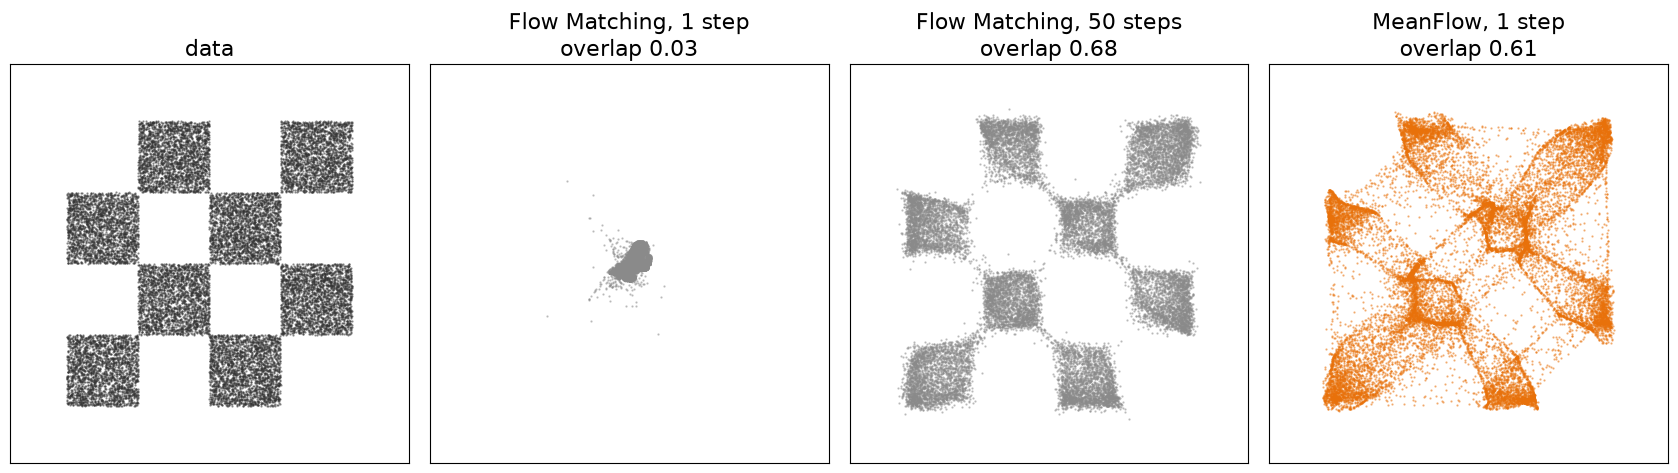

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.8))
show(ax[0], data, "data", "#333")
show(ax[1], sample(nets["fm"], z1, 1, fm=True)[-1], "Flow Matching, 1 step", FM_C)
show(ax[2], sample(nets["fm"], z1, 50, fm=True)[-1], "Flow Matching, 50 steps", FM_C)
show(ax[3], sample(nets["mf"], z1, 1)[-1], "MeanFlow, 1 step", MF_C)
fig.tight_layout(); fig.savefig("figs/1_one_step.png", dpi=150, bbox_inches="tight")

**Why.** Flow Matching's marginal paths curve (paper §3), so one straight Euler step misses. MeanFlow's u is the average velocity along the path: the chord from z₁ to z₀.

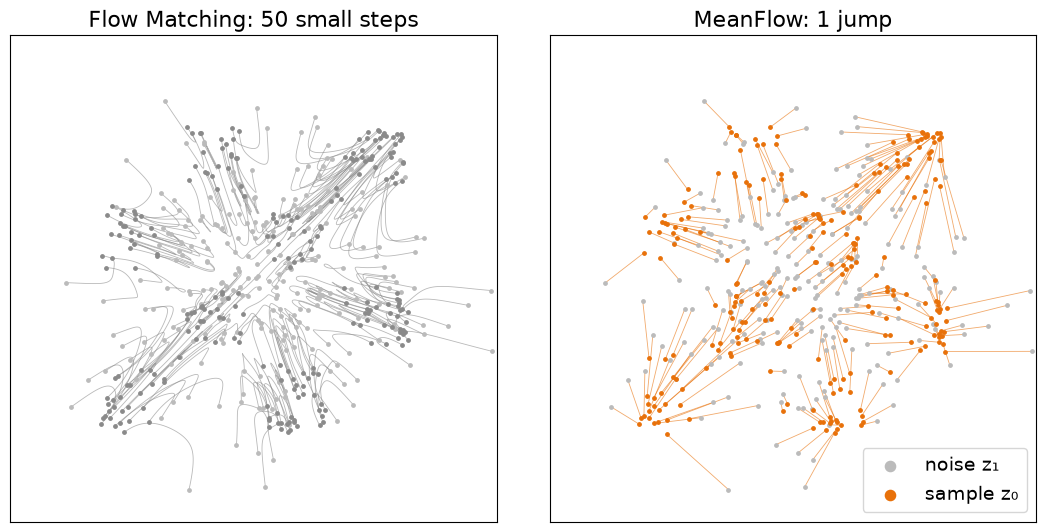

In [7]:
zs = z1[:250]
fm_path, mf_path = sample(nets["fm"], zs, 50, fm=True), sample(nets["mf"], zs, 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 5.4))
for a, P, c, title in [(ax[0], fm_path, FM_C, "Flow Matching: 50 small steps"), (ax[1], mf_path, MF_C, "MeanFlow: 1 jump")]:
    a.plot(P[:, :, 0], P[:, :, 1], c=c, lw=0.6, alpha=0.6)
    a.scatter(*P[0].T, s=6, c="#bbb", zorder=2, label="noise z₁")
    a.scatter(*P[-1].T, s=6, c=c, zorder=3, label="sample z₀")
    a.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect="equal", xticks=[], yticks=[], title=title)
ax[1].legend(loc="lower right", markerscale=3)
fig.tight_layout(); fig.savefig("figs/2_paths.png", dpi=150, bbox_inches="tight")

**Steps vs quality.** MeanFlow at 1 step ≈ Flow Matching at 4 steps. With many steps Flow Matching ends a bit higher, as in the paper (1-step 3.43 vs 250-step 2.06 FID).

fm 1:0.03  2:0.51  4:0.60  8:0.68  16:0.70  50:0.68
mf 1:0.61  2:0.63  4:0.65  8:0.64  16:0.64  50:0.63


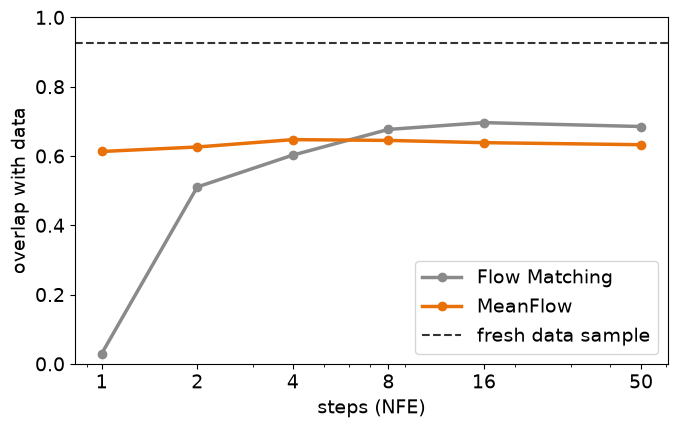

In [8]:
nfes = [1, 2, 4, 8, 16, 50]
q = {k: [overlap(sample(nets[k], z1, n, fm=k == "fm")[-1], data) for n in nfes] for k in ("fm", "mf")}
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(nfes, q["fm"], "o-", c=FM_C, lw=2.5, label="Flow Matching")
ax.plot(nfes, q["mf"], "o-", c=MF_C, lw=2.5, label="MeanFlow")
ax.axhline(overlap(checkerboard(20_000), data), ls="--", c="#333", label="fresh data sample")
ax.set(xscale="log", xticks=nfes, xticklabels=nfes, xlabel="steps (NFE)", ylabel="overlap with data", ylim=(0, 1))
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig("figs/3_nfe.png", dpi=150, bbox_inches="tight")
for k in q: print(k, "  ".join(f"{n}:{o:.2f}" for n, o in zip(nfes, q[k])))

**Break the JVP** (paper Tab. 1b). Same training, wrong tangent for (∂z u, ∂r u, ∂t u). Paper ImageNet 1-step FIDs in brackets; lower is better.

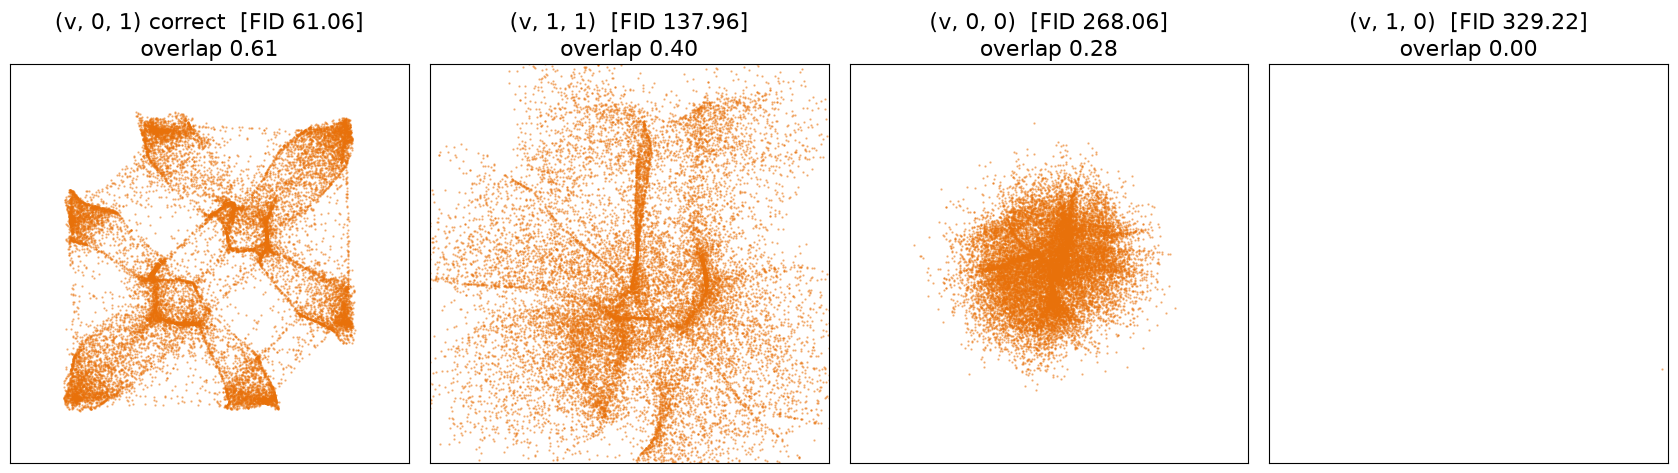

In [9]:
paper = {"mf": ("(v, 0, 1) correct", 61.06), "v11": ("(v, 1, 1)", 137.96), "v00": ("(v, 0, 0)", 268.06), "v10": ("(v, 1, 0)", 329.22)}
fig, ax = plt.subplots(1, 4, figsize=(17, 4.8))
for a, (k, (name, fid)) in zip(ax, paper.items()):
    show(a, sample(nets[k], z1, 1)[-1], f"{name}  [FID {fid}]", MF_C)
fig.tight_layout(); fig.savefig("figs/4_tangent.png", dpi=150, bbox_inches="tight")

Same ordering as the paper. Without ∂t u the net never learns that u should change with the interval, so the jump barely moves the noise; (v, 1, 0) throws every sample off the plot.

---
**Credits.** Method, pseudocode and settings come from the paper (Alg. 1, 2; Tab. 1b; App. A). I wrote the code. I checked `loss_fn` against the first author's PyTorch release ([Gsunshine/py-meanflow](https://github.com/Gsunshine/py-meanflow), `forward_with_loss`): on the same inputs the loss and gradients are identical.